In [19]:
import pandas as pd
pd.set_option("display.max_rows", 200)

CHEMIN = "data/accepted_2007_to_2018Q4.csv.gz"

apercu = pd.read_csv(CHEMIN, nrows=1000)      # quelques milliers de lignes suffisent
print(apercu.shape)

# une ligne par colonne : son nom, son type, un exemple de valeur, le % de valeurs manquantes
inventaire = pd.DataFrame({
    "type": apercu.dtypes,
    "exemple": apercu.iloc[0],
    "pct_manquant": apercu.isna().mean().round(3) * 100,
})
inventaire

(1000, 151)


,type,exemple,pct_manquant
id,int64,68407277,0.0
member_id,float64,NaN,100.0
loan_amnt,float64,3600.0,0.0
funded_amnt,float64,3600.0,0.0
funded_amnt_inv,float64,3600.0,0.0
term,str,36 months,0.0
int_rate,float64,13.99,0.0
installment,float64,123.03,0.0
grade,str,C,0.0
sub_grade,str,C4,0.0


In [20]:
# usecols = ne lire QUE ces colonnes : beaucoup plus rapide
statuts = pd.read_csv(CHEMIN, usecols=["loan_status", "issue_d", "term"])   # ajoute la date d'émission et la durée
statuts["loan_status"].value_counts(dropna = False)                                             # compter chaque valeur

loan_status
Fully Paid                                             1076751
Current                                                 878317
Charged Off                                             268559
Late (31-120 days)                                       21467
In Grace Period                                           8436
Late (16-30 days)                                         4349
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     40
NaN                                                         33
Name: count, dtype: int64

In [21]:
DEFAUT  = ["Charged Off", "Late (31-120 days)","Default"]          # complète
SAIN    = ["Fully Paid", "In Grace Period"]           # complète
EXCLUS  = ["Current", "Does not meet the credit policy. Status:Charged Off","Does not meet the credit policy. Status:Fully Paid","Late (16-30 days)"]              # complète

tous_classes = set(DEFAUT) | set(SAIN) | set(EXCLUS)
presents = set(statuts["loan_status"].dropna().unique())
oublies = presents - tous_classes
assert not oublies, f"Statuts non classés : {oublies}"

statuts["cible"] = statuts["loan_status"].map(
    {**{s: 1 for s in DEFAUT}, **{s: 0 for s in SAIN}}
)                                       # les statuts EXCLUS deviennent NaN
connus = statuts.dropna(subset=["cible"])
print(len(connus), "prêts au statut connu")
print("taux de défaut brut :", connus["cible"].mean())

1375253 prêts au statut connu
taux de défaut brut : 0.21091828194521298


term
36 months    0.169305
60 months    0.339036
Name: cible, dtype: float64


<Axes: title={'center': "Taux de défaut brut par année d'émission"}, xlabel='annee'>

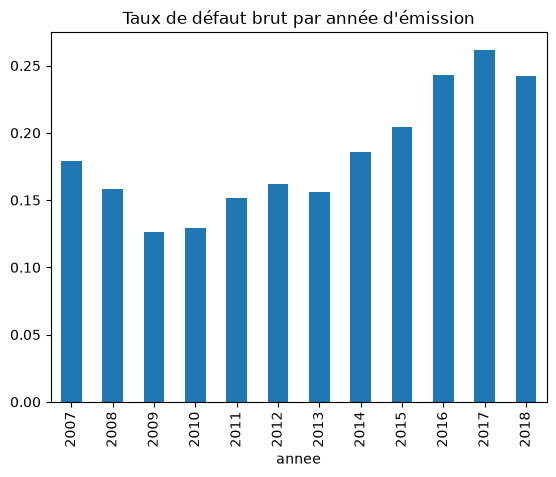

In [22]:
# les dates sont au format "Dec-2015" : %b = mois abrégé en anglais, %Y = année
connus["annee"] = pd.to_datetime(connus["issue_d"], format="%b-%Y").dt.year

print(connus.groupby("term")["cible"].mean())
connus.groupby("annee")["cible"].mean().plot(kind="bar", title="Taux de défaut brut par année d'émission")

In [23]:
import os, matplotlib.pyplot as plt
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/defaut_brut_par_annee.png", dpi=150, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [24]:
# ÉTAPE 1 — POPULATION : prêts de 36 mois arrivés à échéance
ANNEE_MIN, ANNEE_MAX = 2010, 2015

# 1) Vérification : dans ces millésimes, combien de prêts sont ENCORE non terminés ?
statuts["annee"] = pd.to_datetime(statuts["issue_d"], format="%b-%Y").dt.year
perimetre = statuts[(statuts["term"].str.strip() == "36 months")
                    & statuts["annee"].between(ANNEE_MIN, ANNEE_MAX)]
print(perimetre["loan_status"].value_counts(dropna=False), "\n")

# 2) La population de modélisation : même filtre, sur les prêts au statut connu
pop = connus[(connus["term"].str.strip() == "36 months")
             & connus["annee"].between(ANNEE_MIN, ANNEE_MAX)]
print(len(pop), "prêts dans la population")
print("taux de défaut :", round(pop["cible"].mean() * 100, 2), "%\n")

# 3) Taux de défaut et nombre de prêts par millésime
print(pop.groupby("annee")["cible"].agg(nb_prets="size", taux_defaut="mean"))

loan_status
Fully Paid                                             526986
Charged Off                                             85069
Does not meet the credit policy. Status:Fully Paid        532
Does not meet the credit policy. Status:Charged Off       158
Current                                                    72
Late (31-120 days)                                         61
In Grace Period                                             9
Late (16-30 days)                                           5
Name: count, dtype: int64 

612125 prêts dans la population
taux de défaut : 13.91 %

       nb_prets  taux_defaut
annee                       
2010       8466     0.099457
2011      14101     0.106305
2012      43470     0.135795
2013     100422     0.123260
2014     162570     0.137264
2015     283096     0.149041


In [25]:
# ÉTAPE 2 — CHARGEMENT : seulement les colonnes utiles, rangées par rôle
BASE      = ["loan_status", "issue_d", "term"]
VARIABLES = ["loan_amnt", "emp_length", "home_ownership", "annual_inc", "verification_status",
             "purpose", "addr_state", "dti", "fico_range_low", "delinq_2yrs", "inq_last_6mths",
             "open_acc", "pub_rec", "revol_bal", "revol_util", "total_acc", "earliest_cr_line",
             "mort_acc", "pub_rec_bankruptcies", "application_type"]   # connues à l'octroi → modèle
ETALON    = ["grade", "sub_grade", "int_rate"]                        # sorties de Lending Club → comparaison
POST      = ["funded_amnt", "total_rec_prncp", "recoveries", "collection_recovery_fee","total_pymnt"]
            # connues APRÈS : INTERDITES au modèle, réservées au calcul de la LGD (étape 6)

df = pd.read_csv(CHEMIN, usecols=BASE + VARIABLES + ETALON + POST, low_memory=False)

# même cible et même population qu'à l'étape 1
df = df[df["loan_status"].isin(DEFAUT + SAIN)].copy()
df["cible"] = df["loan_status"].isin(DEFAUT).astype(int)
df["annee"] = pd.to_datetime(df["issue_d"], format="%b-%Y").dt.year
df = df[(df["term"].str.strip() == "36 months") & df["annee"].between(ANNEE_MIN, ANNEE_MAX)].copy()

assert len(df) == len(pop), "la population ne correspond pas à l'étape 1"
print(df.shape)

# % de valeurs manquantes des variables du modèle (les 8 pires)
print(df[VARIABLES].isna().mean().sort_values(ascending=False).head(8).round(4) * 100)

# sauvegarde : les prochains notebooks reliront ce fichier en 2 secondes au lieu de 2 minutes
df.to_parquet("data/population.parquet")

(612125, 33)
emp_length             5.90
mort_acc               4.67
revol_util             0.05
dti                    0.00
annual_inc             0.00
home_ownership         0.00
loan_amnt              0.00
verification_status    0.00
dtype: float64


In [26]:
# taux de défaut par grade Lending Club
print(df.groupby("grade")["cible"].agg(nb_prets="size", taux_defaut="mean").round(3), "\n")

# taux de défaut par tranche de score FICO
df["tranche_fico"] = pd.cut(df["fico_range_low"], bins=[600, 680, 700, 720, 750, 850], right=False)
print(df.groupby("tranche_fico", observed=True)["cible"].agg(nb_prets="size", taux_defaut="mean").round(3))

       nb_prets  taux_defaut
grade                       
A        141388        0.055
B        209730        0.112
C        160119        0.179
D         75141        0.234
E         21081        0.287
F          4173        0.330
G           493        0.400 

              nb_prets  taux_defaut
tranche_fico                       
[600, 680)      216740        0.183
[680, 700)      167341        0.148
[700, 720)      110064        0.112
[720, 750)       73879        0.083
[750, 850)       44101        0.052


In [27]:
%pip install scikit-learn lightgbm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
